# Event-Gated Person Tracking and Interaction Analysis

How many person-stage calls does a gate avoid, and which frames still have tracked people? This walkthrough uses the same package and outputs as the VS Code demo. The boxes and trigger inputs are generated. The independent recorded-video comparison is in `evaluation/results.md`.

In [1]:
import csv
import json
from pathlib import Path
import subprocess
import sys
from tempfile import mkdtemp

cwd = Path.cwd()
project = next(path for path in (cwd, *cwd.parents) if (path / 'src/tracking_analysis').is_dir())
output_root = project / 'outputs'
output_root.mkdir(exist_ok=True)
run_folder = Path(mkdtemp(prefix='notebook-', dir=output_root))
demo = project / 'assets/demo'
summaries = {}
for mode in ('continuous', 'gated'):
    run_output = run_folder / mode
    subprocess.run(
        [sys.executable, '-m', 'src.tracking_analysis', 'run',
         '--video', str(demo / 'approach-and-separate.mp4'),
         '--replay', str(demo / 'triggers.json'),
         '--mode', mode, '--output', str(run_output)],
        cwd=project, check=True, capture_output=True, text=True,
    )
    summary = json.loads((run_output / 'summary.json').read_text(encoding='utf-8'))
    summaries[mode] = summary
    print(f'{mode.capitalize():10} {summary["active_frames"]:2}/{summary["frame_count"]} active frames, '
          f'{summary["person_stage_calls"]:2} person-stage calls')

Continuous 54/54 active frames, 54 person-stage calls
Gated      34/54 active frames, 34 person-stage calls


## Trace the gate and tracks

At 20 FPS, the 0.8-second grace period includes the trigger frame plus 16 more frames. The two expected gates run from frames 4 to 20 and 30 to 46 inclusive. The error at frame 9 cannot extend the first window.

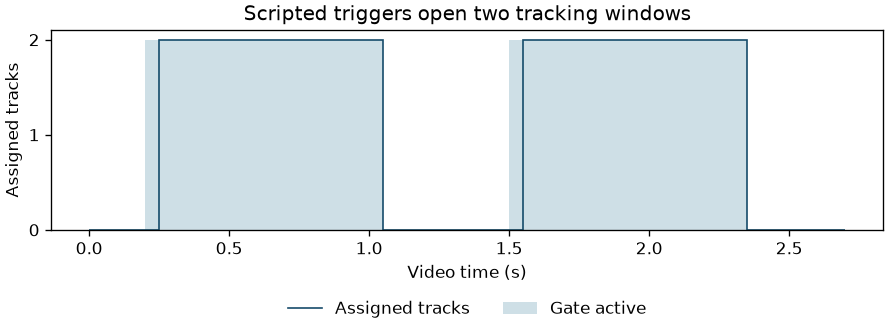

In [2]:
import matplotlib.pyplot as plt

gated = run_folder / 'gated'
with (gated / 'frames.csv').open(newline='', encoding='utf-8') as frame_file:
    frames = list(csv.DictReader(frame_file))
assert [int(row['frame_id']) for row in frames if row['event_id']] == [
    *range(4, 21), *range(30, 47)
]
seconds = [float(row['timestamp_s']) for row in frames]
active = [int(bool(row['event_id'])) for row in frames]
counts = [int(row['person_count']) for row in frames]
edges = [*seconds, seconds[-1] + 1 / summaries['gated']['fps']]
fig, ax = plt.subplots(figsize=(7.4, 2.7), layout='constrained')
ax.stairs(counts, edges, color='#164c6b', label='Assigned tracks')
ax.stairs([2 * value for value in active], edges, fill=True, color='#cedfe6',
          label='Gate active', zorder=0)
ax.set(title='Scripted triggers open two tracking windows', xlabel='Video time (s)',
       ylabel='Assigned tracks', yticks=[0, 1, 2])
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncols=2, frameon=False)
plt.show()

In [3]:
with (gated / 'pairs.csv').open(newline='', encoding='utf-8') as pair_file:
    pairs = list(csv.DictReader(pair_file))
for row in [row for row in pairs if int(row['frame_id']) in (12, 14, 34, 36)]:
    print(f'Frame {row["frame_id"]}, event {row["event_id"]}, '
          f'pair {row["track_id_a"]}/{row["track_id_b"]}, '
          f'{float(row["distance_px"]):.1f} px, {row["interaction_status"]}')
print('The bundled example video is outputs/example/annotated.mp4.')

Frame 12, event 1, pair 0/1, 194.8 px, approaching
Frame 14, event 1, pair 0/1, 178.9 px, approaching
Frame 34, event 2, pair 0/1, 139.2 px, moving_apart
Frame 36, event 2, pair 0/1, 155.0 px, moving_apart
The bundled example video is outputs/example/annotated.mp4.


The pair in one event belongs to that event. Even when the same raw IDs recur, the observations and durations are computed independently. This example verifies geometry and event timing under known inputs. It supplies no estimate of detector accuracy.